# Reto básico 3: modelo de clustering (K-Means)

**Entrada:** `data/processed/features_modelo.csv` (reto 2: 13 features escaladas, una fila por cliente segmentable).

Contenido:
1. K-Means para k = 2 … 10.
2. Método del codo (inercia).
3. Silhouette Score para cada k.
4. Elección y justificación de k.
5. Modelo final y distribución de clientes por clúster.

**Salidas:** `data/processed/segmentos_kmeans.csv` (cliente → clúster) y `data/processed/centroides_kmeans.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

X = pd.read_csv(PROC / "features_modelo.csv", dtype={"client_id": str}).set_index("client_id")
print(X.shape)

(172623, 13)


## 1–3. K-Means para k = 2…10: codo y silhouette

- **Inercia:** suma de distancias al cuadrado de cada cliente a su centroide. Se calcula sobre todos los clientes.
- **Silhouette:** su coste es O(n²), así que se calcula sobre una **muestra fija de 20.000 clientes**, la misma para
  todos los k. Con ese tamaño el error de estimación es despreciable.
- Como apoyo se añaden **Davies-Bouldin** (menor es mejor) y **Calinski-Harabasz** (mayor es mejor).

In [3]:
K_RANGE = range(2, 11)
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(X), size=20_000, replace=False)
filas = []
modelos = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    modelos[k] = km
    lab = km.labels_
    filas.append({"k": k, "inercia": km.inertia_,
                  "silhouette": silhouette_score(X.iloc[muestra], lab[muestra]),
                  "davies_bouldin": davies_bouldin_score(X.iloc[muestra], lab[muestra]),
                  "calinski_harabasz": calinski_harabasz_score(X.iloc[muestra], lab[muestra]),
                  "tamaño_min_%": np.bincount(lab).min() / len(lab) * 100})
metricas = pd.DataFrame(filas).set_index("k")
metricas["caída_inercia_%"] = -metricas.inercia.pct_change() * 100
metricas

,inercia,silhouette,davies_bouldin,calinski_harabasz,tamaño_min_%,caída_inercia_%
k,,,,,,
2,"2,007,095.942",0.135,2.682,"2,386.449",33.995,NaN
3,"1,813,423.890",0.165,2.227,"2,380.089",10.899,9.649
4,"1,682,260.729",0.141,2.313,"2,225.306",10.318,7.233
5,"1,517,918.033",0.149,1.974,"2,370.906",5.058,9.769
6,"1,427,836.869",0.145,1.909,"2,265.451",4.554,5.935
7,"1,331,997.083",0.158,1.824,"2,259.820",4.468,6.712
8,"1,263,980.541",0.163,1.739,"2,201.365",4.214,5.106
9,"1,212,771.315",0.170,1.697,"2,121.806",4.184,4.051
10,"1,176,237.418",0.151,1.723,"2,002.635",4.169,3.012


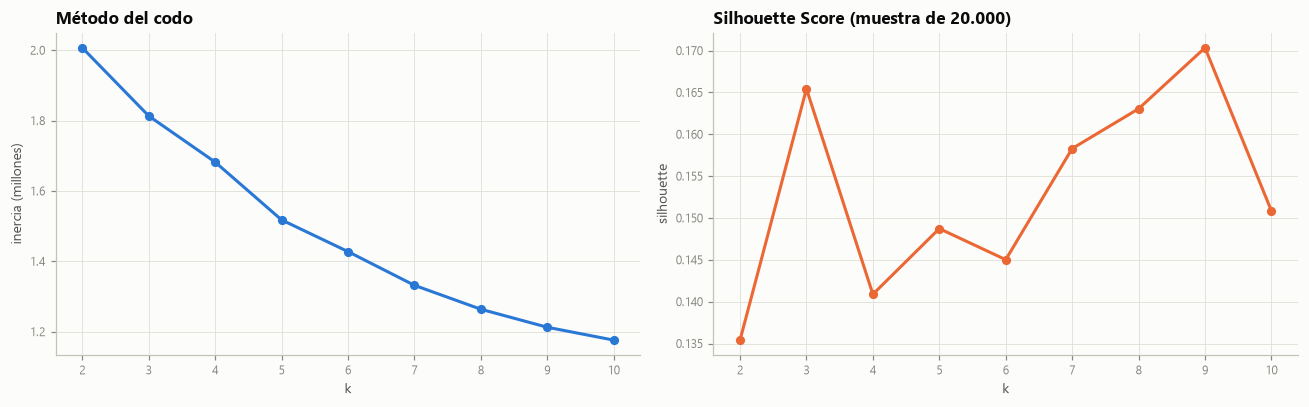

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(metricas.index, metricas.inercia / 1e6, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("Método del codo"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inercia (millones)")
axes[1].plot(metricas.index, metricas.silhouette, color=CAT[1], lw=2, marker="o", ms=5)
axes[1].set_title("Silhouette Score (muestra de 20.000)"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
for ax in axes:
    ax.set_xticks(list(K_RANGE))
save(fig, "r3_codo_silhouette.png")

## 4. Elección de k

Criterio:
1. **Silhouette** lo más alto posible.
2. **Codo:** a partir de k, añadir un clúster más aporta cada vez menos reducción de inercia.
3. **Utilidad de negocio:** entre 4 y 8 segmentos, todos con al menos un 3 % de los clientes (un equipo de marketing
   no puede gestionar 2 segmentos ni 10 microsegmentos).

Se elige el k con mejor silhouette dentro del rango de negocio. Si dos k están a menos de 0,01 de silhouette, se
prefiere el que tiene mejor Davies-Bouldin.

In [5]:
cand = metricas.loc[4:8]
cand = cand[cand["tamaño_min_%"] >= 3]
mejor = cand.silhouette.max()
empatados = cand[cand.silhouette >= mejor - 0.01]
K_OPT = int(empatados.davies_bouldin.idxmin())
show_md(f"**k elegido = {K_OPT}**: silhouette = {metricas.loc[K_OPT, 'silhouette']:.3f}, "
        f"Davies-Bouldin = {metricas.loc[K_OPT, 'davies_bouldin']:.3f}, clúster más pequeño = "
        f"{metricas.loc[K_OPT, 'tamaño_min_%']:.1f} % de los clientes. Mejor silhouette absoluto: "
        f"k = {int(metricas.silhouette.idxmax())} ({metricas.silhouette.max():.3f}). La caída de inercia al pasar a "
        f"k = {K_OPT + 1} es del {metricas.loc[K_OPT + 1, 'caída_inercia_%']:.1f} %, frente al "
        f"{metricas.loc[K_OPT, 'caída_inercia_%']:.1f} % del paso anterior.")

**k elegido = 8**: silhouette = 0.163, Davies-Bouldin = 1.739, clúster más pequeño = 4.2 % de los clientes. Mejor silhouette absoluto: k = 9 (0.170). La caída de inercia al pasar a k = 9 es del 4.1 %, frente al 5.1 % del paso anterior.

## 5. Modelo final y distribución por clúster

,clientes,%
cluster,,
0,13913,8.060
1,31910,18.485
2,35039,20.298
3,21574,12.498
4,16992,9.843
5,27633,16.008
6,18287,10.594
7,7275,4.214


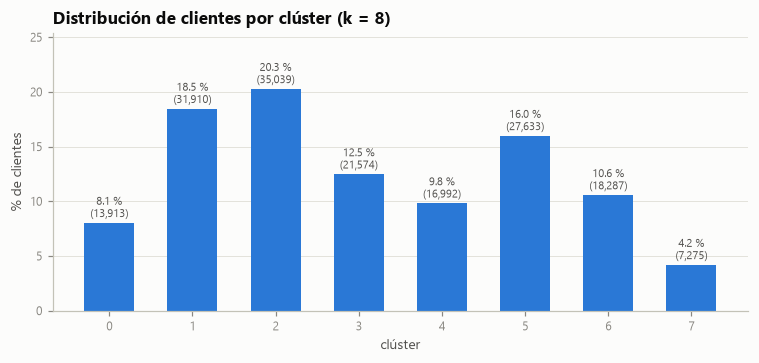

In [6]:
km = modelos[K_OPT]
labels = pd.Series(km.labels_, index=X.index, name="cluster")
dist = labels.value_counts().sort_index().rename("clientes").to_frame()
dist["%"] = dist.clientes / dist.clientes.sum() * 100
display(dist)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(dist.index.astype(str), dist["%"], width=0.6, color=BLUE)
for i, v in enumerate(dist["%"]):
    ax.text(i, v + 0.5, f"{v:.1f} %\n({dist.clientes.iloc[i]:,})", ha="center", fontsize=7.5, color=INK2)
ax.set_xlabel("clúster"); ax.set_ylabel("% de clientes"); ax.grid(axis="x", visible=False)
ax.set_title(f"Distribución de clientes por clúster (k = {K_OPT})")
ax.set_ylim(0, dist["%"].max() * 1.25)
save(fig, "r3_distribucion_clusters.png")

Silhouette por clúster sobre la muestra: indica qué segmentos están mejor definidos.

In [7]:
from sklearn.metrics import silhouette_samples

sil = pd.Series(silhouette_samples(X.iloc[muestra], km.labels_[muestra]), name="silhouette")
sil_cl = sil.groupby(km.labels_[muestra]).agg(["mean", "median", lambda s: (s < 0).mean() * 100])
sil_cl.columns = ["silhouette medio", "silhouette mediano", "% clientes con silhouette < 0"]
sil_cl.index.name = "cluster"
sil_cl

,silhouette medio,silhouette mediano,% clientes con silhouette < 0
cluster,,,
0,0.115,0.119,3.761
1,0.119,0.124,1.393
2,0.199,0.204,0.000
3,0.146,0.152,0.080
4,0.277,0.289,0.509
5,0.148,0.155,3.683
6,0.100,0.106,5.481
7,0.282,0.300,5.012


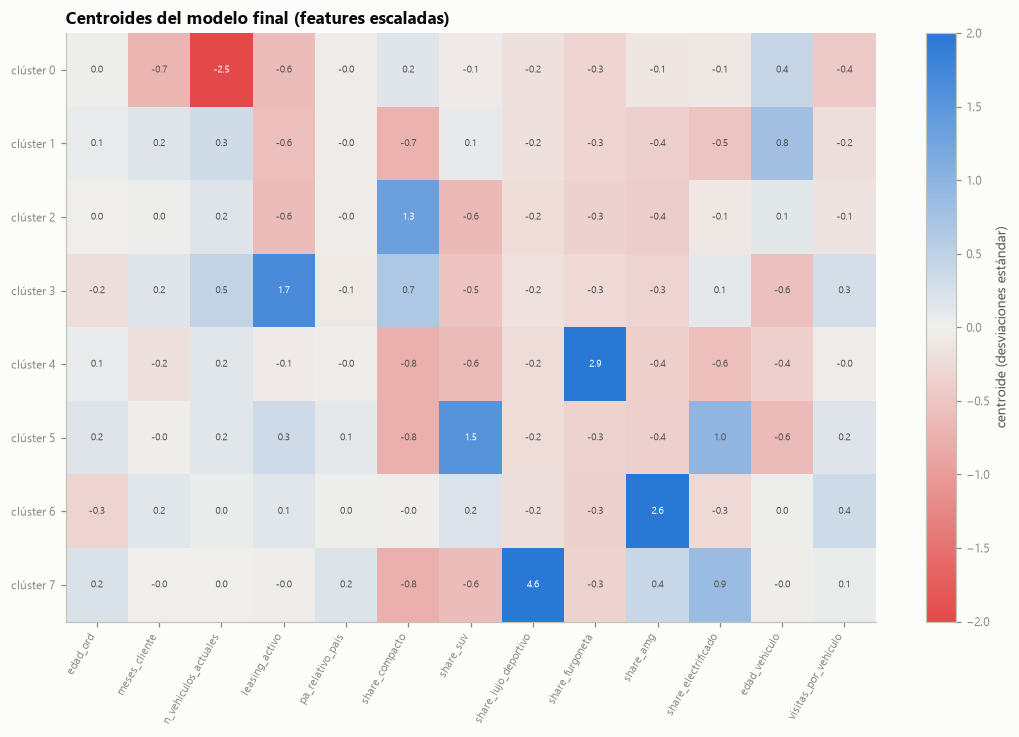

In [8]:
centroides = pd.DataFrame(km.cluster_centers_, columns=X.columns)
centroides.index.name = "cluster"
labels.to_frame().to_csv(PROC / "segmentos_kmeans.csv")
centroides.to_csv(PROC / "centroides_kmeans.csv")
metricas.to_csv(PROC / "metricas_kmeans.csv")
fig, ax = plt.subplots(figsize=(10, 0.6 * K_OPT + 2))
import matplotlib.colors as mcolors
im = ax.imshow(centroides.values, cmap=mcolors.LinearSegmentedColormap.from_list("div", DIV), vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(X.shape[1])); ax.set_xticklabels(X.columns, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(K_OPT)); ax.set_yticklabels([f"clúster {i}" for i in range(K_OPT)])
ax.grid(False)
for i in range(K_OPT):
    for j in range(X.shape[1]):
        ax.text(j, i, f"{centroides.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(centroides.values[i, j]) > 1.2 else INK2)
fig.colorbar(im, ax=ax, label="centroide (desviaciones estándar)")
ax.set_title("Centroides del modelo final (features escaladas)")
save(fig, "r3_centroides.png")